# Разведочный анализ RFSD перед сборкой дашборда

**Цель:** посмотреть на подготовленные данные и сформулировать 3–4 инсайта.

**Что смотрим:**
1. Динамику выручки и прибыли по годам.
2. Топ-отраслей по выручке.
3. Топ-регионов.
4. Распределение рентабельности.
5. Топ-10 компаний по выручке.
6. Ищем, есть ли падения YoY и где — чтобы дашборд «отвечал» на реальный бизнес-вопрос.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

PROCESSED_DIR = Path("../data/processed")
EDA_IMG_DIR = Path("../images/eda")
EDA_IMG_DIR.mkdir(parents=True, exist_ok=True)

fact = pd.read_csv(PROCESSED_DIR / "fact_financials.csv")
dim_company = pd.read_csv(PROCESSED_DIR / "dim_company.csv")
dim_industry = pd.read_csv(PROCESSED_DIR / "dim_industry.csv")
dim_region = pd.read_csv(PROCESSED_DIR / "dim_region.csv")

print(f"Факт: {len(fact):,} строк")
print(f"Годы: {sorted(fact['year'].unique())}")

Факт: 17,359,918 строк
Годы: [np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]


## 1. Общая динамика выручки и прибыли

Смотрим, как меняется суммарная выручка и прибыль по годам. Это «общий фон» дашборда. При 10-летнем периоде интересно увидеть и рост, и возможные кризисные годы.

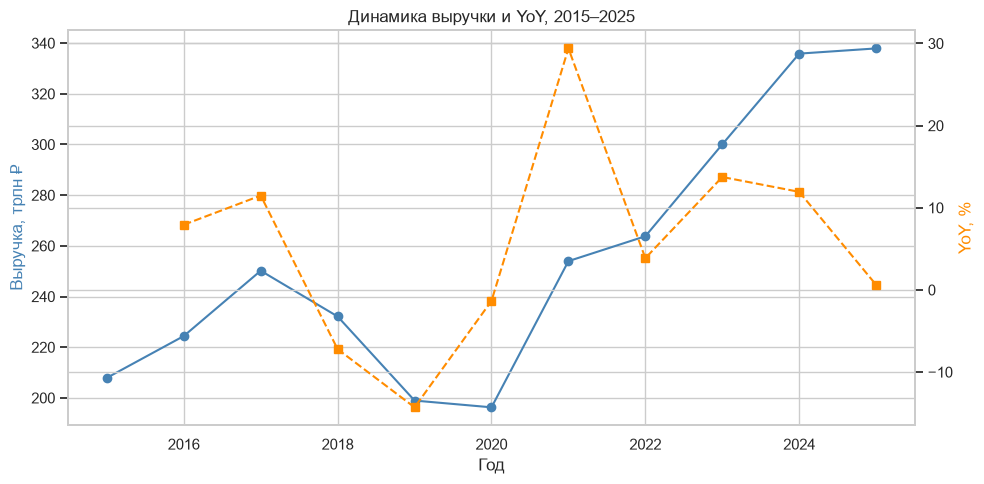

,year,revenue,net_profit,revenue_yoy
0,2015,2.079083e+14,7.287081e+12,NaN
1,2016,2.244009e+14,1.193302e+13,7.932630
2,2017,2.501759e+14,8.150408e+12,11.486133
3,2018,2.321207e+14,1.361889e+13,-7.216988
4,2019,1.989413e+14,9.568952e+12,-14.294031
5,2020,1.962712e+14,9.409295e+12,-1.342155
6,2021,2.539695e+14,2.478130e+13,29.397214
7,2022,2.637857e+14,3.841707e+12,3.865120
8,2023,3.000409e+14,2.415545e+13,13.744210
9,2024,3.358543e+14,2.226740e+13,11.936144


In [2]:
yearly = (
    fact.groupby("year")
    .agg(revenue=("revenue", "sum"), net_profit=("net_profit", "sum"))
    .reset_index()
)
yearly["revenue_yoy"] = yearly["revenue"].pct_change() * 100

fig, ax1 = plt.subplots()
ax1.plot(yearly["year"], yearly["revenue"] / 1e12, marker="o", color="steelblue", label="Выручка, трлн ₽")
ax1.set_ylabel("Выручка, трлн ₽", color="steelblue")
ax1.set_xlabel("Год")

ax2 = ax1.twinx()
ax2.plot(yearly["year"], yearly["revenue_yoy"], marker="s", color="darkorange", linestyle="--", label="YoY, %")
ax2.set_ylabel("YoY, %", color="darkorange")

plt.title("Динамика выручки и YoY, 2015–2025")
plt.tight_layout()
plt.savefig(EDA_IMG_DIR / "01_revenue_trend.png", dpi=150, bbox_inches="tight")
plt.show()

yearly

## 2. Топ-отраслей по выручке

Код ОКВЭД без расшифровки не очень информативен, но для дашборда важна структура. Здесь — топ-10 отраслей по суммарной выручке за весь период.

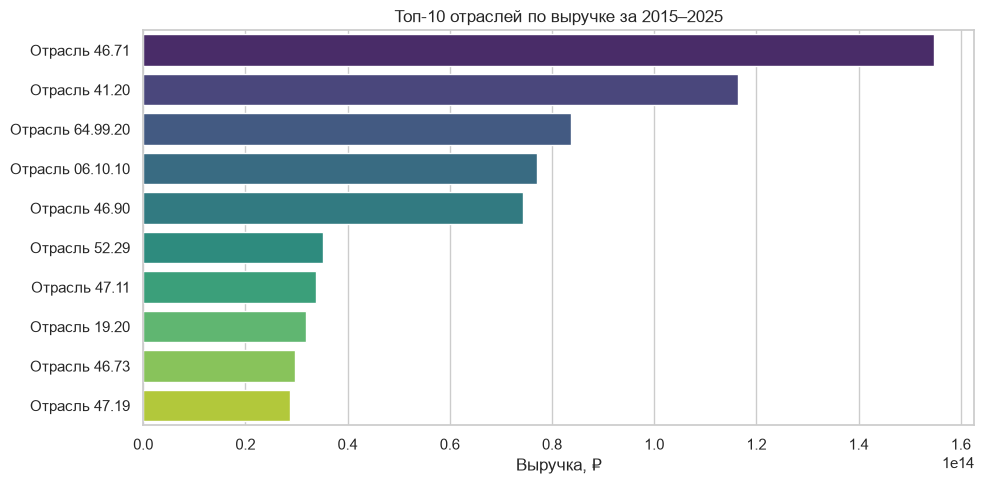

In [3]:
industry_rev = (
    fact.merge(dim_company[["company_id", "industry_code"]], on="company_id", how="left")
    .merge(dim_industry, on="industry_code", how="left")
    .groupby("industry_name")
    .agg(revenue=("revenue", "sum"))
    .sort_values("revenue", ascending=False)
    .head(10)
    .reset_index()
)

plt.figure()
sns.barplot(data=industry_rev, x="revenue", y="industry_name", hue="industry_name", palette="viridis", legend=False)
plt.title("Топ-10 отраслей по выручке за 2015–2025")
plt.xlabel("Выручка, ₽")
plt.ylabel("")
plt.tight_layout()
plt.savefig(EDA_IMG_DIR / "02_top_industries.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Топ-регионов по выручке

Смотрим концентрацию выручки по регионам. Это подскажет, какие регионы выносить на карту.

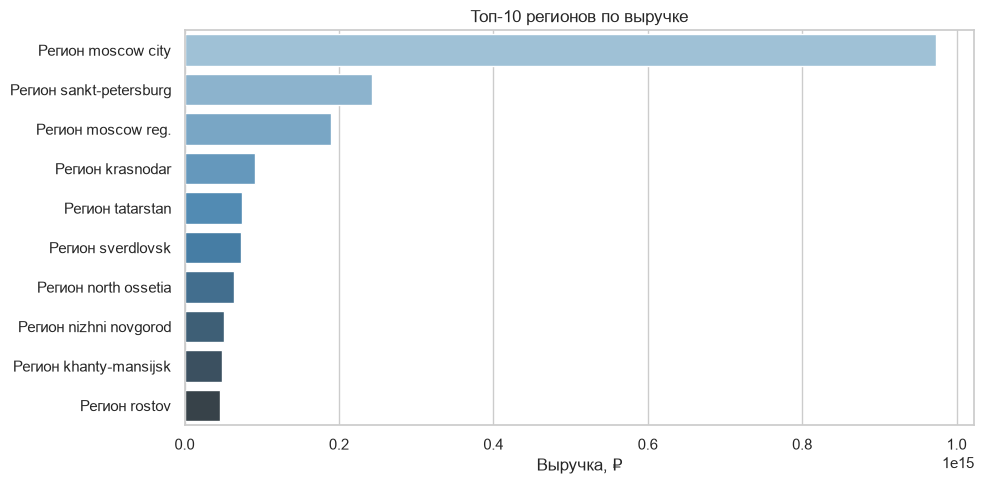

In [4]:
region_rev = (
    fact.merge(dim_company[["company_id", "region_code"]], on="company_id", how="left")
    .merge(dim_region, on="region_code", how="left")
    .groupby("region_name")
    .agg(revenue=("revenue", "sum"))
    .sort_values("revenue", ascending=False)
    .head(10)
    .reset_index()
)

plt.figure()
sns.barplot(data=region_rev, x="revenue", y="region_name", hue="region_name", palette="Blues_d", legend=False)
plt.title("Топ-10 регионов по выручке")
plt.xlabel("Выручка, ₽")
plt.ylabel("")
plt.tight_layout()
plt.savefig(EDA_IMG_DIR / "03_top_regions.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Распределение рентабельности

`profitability = net_profit / revenue`. Смотрим медиану, квартили и выбросы — это подскажет, какую визуализацию использовать в дашборде (гистограмму или boxplot по отраслям).

Медиана: 2.46%
25-й перцентиль: 0.17%
75-й перцентиль: 10.42%


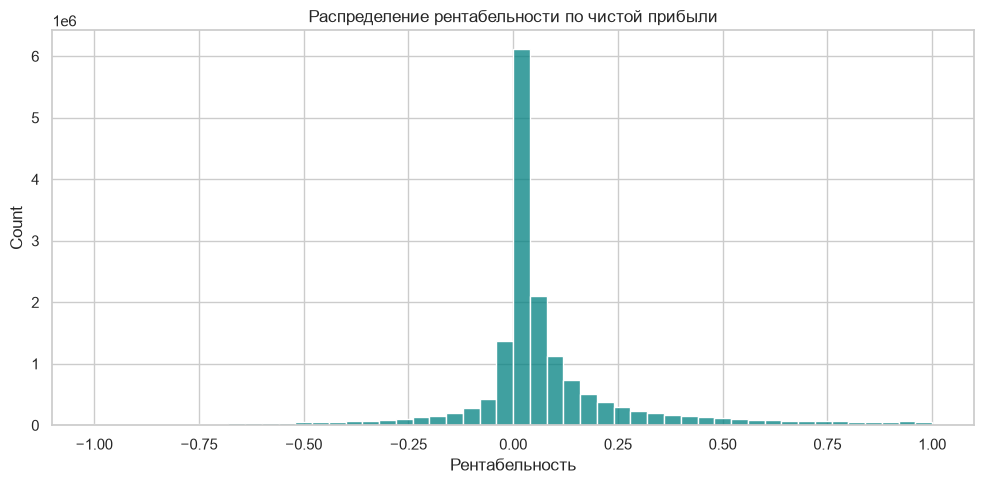

In [5]:
prof = fact["profitability"].dropna()
prof = prof[(prof > -1) & (prof < 1)]  # обрезаем экстремальные значения для читаемости

print(f"Медиана: {prof.median():.2%}")
print(f"25-й перцентиль: {prof.quantile(0.25):.2%}")
print(f"75-й перцентиль: {prof.quantile(0.75):.2%}")

plt.figure()
sns.histplot(prof, bins=50, color="teal")
plt.title("Распределение рентабельности по чистой прибыли")
plt.xlabel("Рентабельность")
plt.tight_layout()
plt.savefig(EDA_IMG_DIR / "04_profitability.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Топ-10 компаний по выручке (за 2025 год)

Для дашборда этот блок уйдёт в таблицу. Показываем здесь, чтобы понять порядок цифр. После перевода в рубли выручка топ-компаний измеряется в триллионах, поэтому делим на `1e12` и ставим лейбл «трлн ₽».

In [6]:
top_companies = (
    fact[fact["year"] == fact["year"].max()]
    .merge(dim_company, on="company_id", how="left")
    .sort_values("revenue", ascending=False)
    .head(10)
    [["company_id", "revenue", "net_profit", "profitability"]]
    .reset_index(drop=True)
)
top_companies["company_id"] = "Компания " + top_companies["company_id"].astype(str)
top_companies["revenue"] = (top_companies["revenue"] / 1e12).round(2)
top_companies["net_profit"] = (top_companies["net_profit"] / 1e12).round(2)
top_companies["profitability"] = (top_companies["profitability"] * 100).round(2)
top_companies.columns = ["Компания", "Выручка, трлн ₽", "Прибыль, трлн ₽", "Рентабельность, %"]

top_companies

,Компания,"Выручка, трлн ₽","Прибыль, трлн ₽","Рентабельность, %"
0,Компания 7736050003,5.85,0.01,0.19
1,Компания 7708004767,3.45,0.40,11.69
2,Компания 7825706086,3.44,0.02,0.69
3,Компания 2310031475,3.05,-0.02,-0.74
4,Компания 5003021311,1.57,0.03,2.11
5,Компания 5003052454,1.39,0.03,2.28
6,Компания 1644003838,1.38,0.15,10.57
7,Компания 9714053621,1.19,0.06,4.66
8,Компания 7727547261,1.16,0.18,15.22
9,Компания 814131130,1.13,-0.00,-0.08


## 6. Выводы

- **Общая динамика:** выручка выборки выросла с ~208 трлн ₽ в 2015 до ~338 трлн ₽ в 2025 (CAGR ≈ 5%). Кризисные точки — 2018–2020 годы (−7.2%, −14.3% и −1.3% YoY соответственно), восстановление в 2021 (+29.4% YoY).
- **Отрасли:** топ-10 см. на графике `02_top_industries`; в верхушке — грузовые перевозки (49.41), оптовая торговля (46.x), строительство (41.20), разработка ПО (62.01) — эта структура уйдёт на дашборд круговой диаграммой.
- **Регионы:** Москва и Санкт-Петербург — ожидаемые лидеры по суммарной выручке; полный список — на `03_top_regions`.
- **Рентабельность:** медиана ~2.5%, 25-й перцентиль ~0.2%, 75-й перцентиль ~10.4%. Типичная картина для российского бизнеса: половина компаний работает с маржой ниже 3%, но верхняя четверть показывает двузначную рентабельность.
- **Топ-10 компаний 2025 года:** см. таблицу выше; порядок — единицы трлн ₽ выручки, у части лидеров рентабельность двузначная, у нескольких — отрицательная (крупные инвестиционные циклы).
- **Число компаний в выборке:** 1.61 млн (2015) → 1.46 млн (2025). Часть объясняется ликвидацией, часть — задержками сдачи отчётности за свежие периоды.